# original LR

In [8]:
# import libs
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt  # 关键导入
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

In [9]:
# read data
df = pd.read_csv(r'C:\Users\53268\Documents\internship\code\code_internship\dataset\data_prepared.csv')
df.head()

,material,stroke,osc_freq,force,cycle,coe,Absolute Energy,Amplitude,ASL,Average Frequency,Initiation Frequency,Parametric 1,Parametric 2,Peak Frequency,Reverberation Frequency,Threshold,stage
0,steel-glass,100,10,10,1,0.023768,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,one
1,steel-glass,100,10,10,2,0.024692,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,one
2,steel-glass,100,10,10,3,0.024137,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,one
3,steel-glass,100,10,10,4,0.024139,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,one
4,steel-glass,100,10,10,5,0.023798,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,one


In [10]:
# features and labels
X = df.drop(columns=['material', 'stroke', 'stage', 'cycle'])
y = df['stage']

# use stratufy to make sure the test data includes all labels.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y)
print("数据集信息:")
print(f"特征数: {X.shape[1]}, 样本数: {X.shape[0]}, 类别数: {len(np.unique(y))}")

数据集信息:
特征数: 13, 样本数: 4838, 类别数: 5


In [11]:
# 特征标准化（重要：逻辑回归对特征尺度敏感）
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [12]:
# 3. 创建并训练逻辑回归模型
# 使用multi_class='multinomial'处理5分类问题
# solver='lbfgs'适用于中小型数据集
model = LogisticRegression(
    multi_class='multinomial',  # 多分类设置
    solver='lbfgs',             # 优化算法
    max_iter=1000,              # 增加迭代次数确保收敛
    random_state=42,
    class_weight='balanced'    # 处理类别不平衡（如果存在）
)

# 训练模型
model.fit(X_train_scaled, y_train)

f:\python\Lib\site-packages\sklearn\linear_model\_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


LogisticRegression(class_weight='balanced', max_iter=1000,
                   multi_class='multinomial', random_state=42)

Accuracy: 0.63

Classification report of Logistic Regression model:
              precision    recall  f1-score   support

        five       0.53      0.41      0.46       333
        four       0.66      0.61      0.63       441
         one       0.91      0.99      0.95       328
       three       0.27      0.47      0.34       126
         two       0.57      0.54      0.56       224

    accuracy                           0.63      1452
   macro avg       0.59      0.60      0.59      1452
weighted avg       0.64      0.63      0.63      1452


Feature importance of Logistic Regression model:
coe                        2.519342
osc_freq                   0.834409
ASL                        0.798876
Parametric 1               0.739353
Threshold                  0.647979
Amplitude                  0.567994
Parametric 2               0.545494
force                      0.458820
Peak Frequency             0.409580
Absolute Energy            0.176524
Initiation Frequency       0.1757

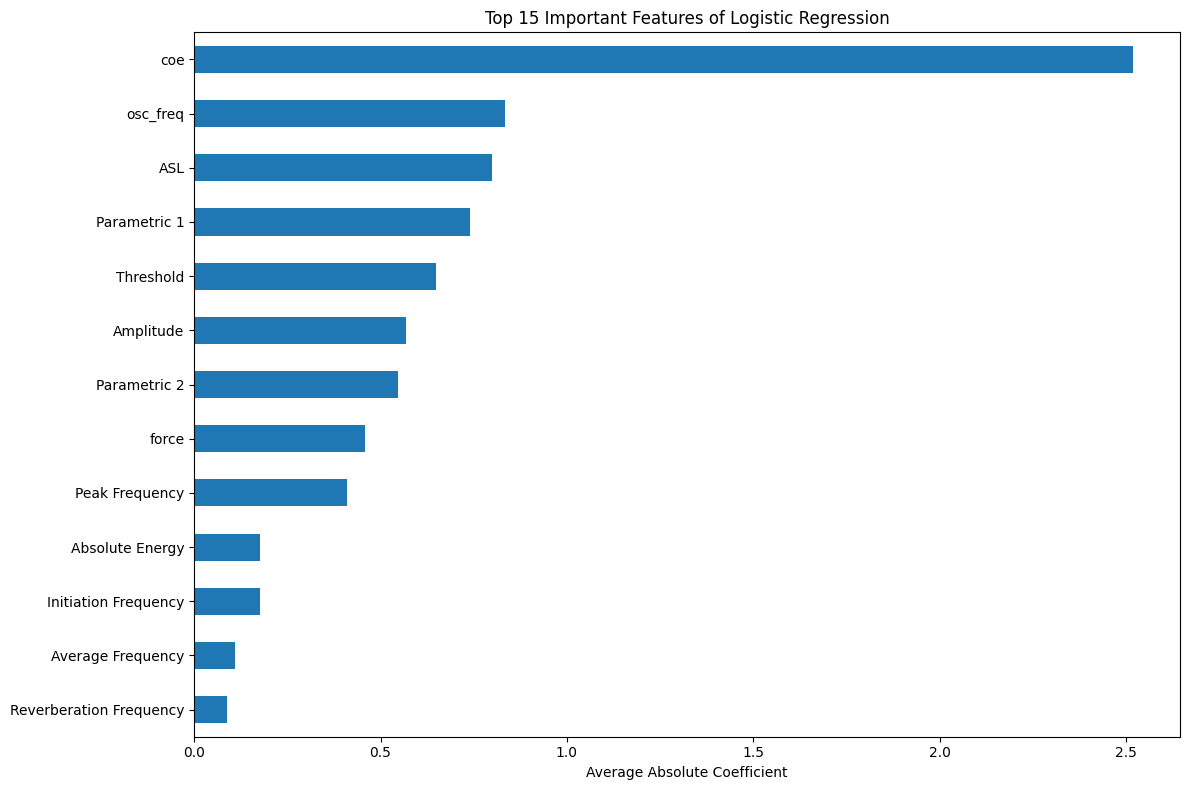

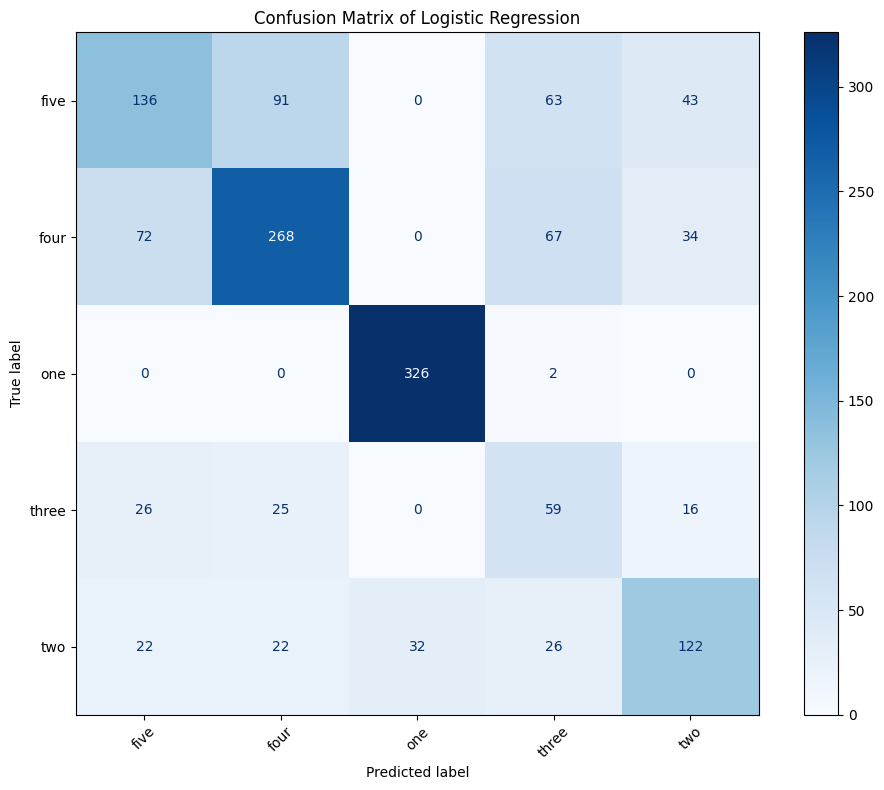

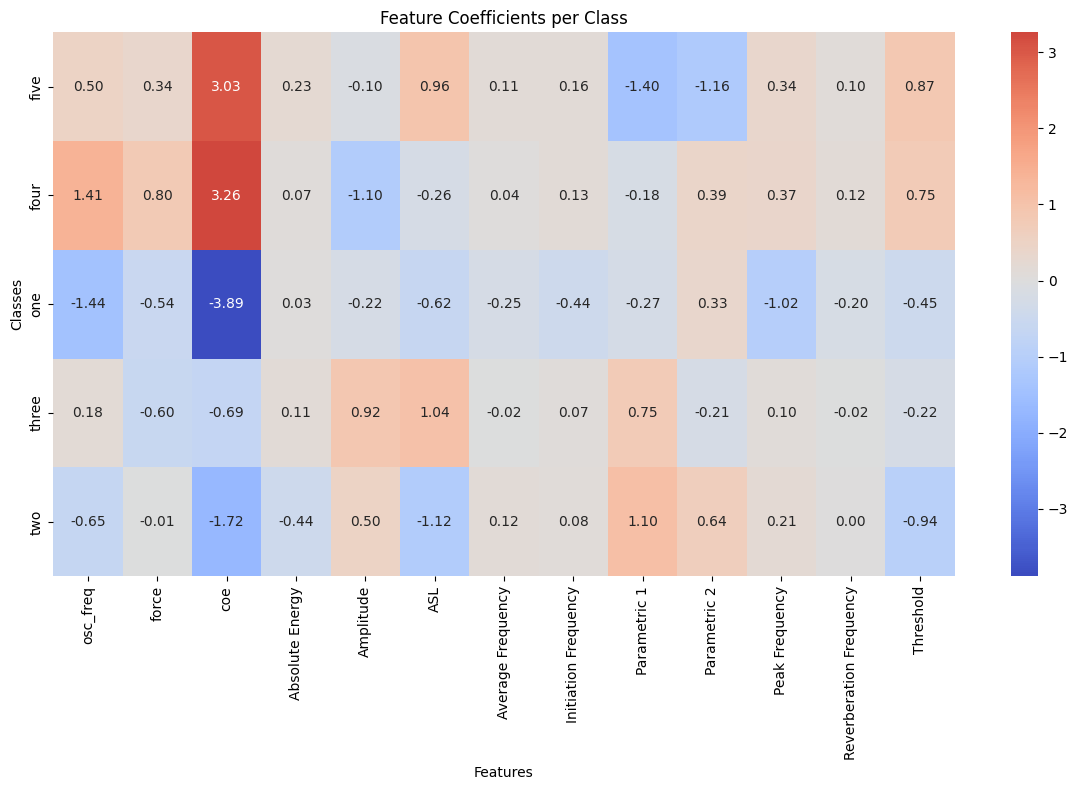

In [13]:
# 4. 模型评估
# 预测测试集
y_pred = model.predict(X_test_scaled)

# 模型评估
print(f"Accuracy: {accuracy_score(y_test, y_pred):.2f}")
print("\nClassification report of Logistic Regression model:")
print(classification_report(y_test, y_pred, target_names=model.classes_.astype(str)))

# 特征重要性分析（使用系数的绝对值平均值）
feature_importances = pd.Series(
    np.abs(model.coef_).mean(axis=0),  # 取所有类别系数的绝对值的平均值
    index=X.columns
)
print("\nFeature importance of Logistic Regression model:")
print(feature_importances.sort_values(ascending=False))

# 可视化特征重要性
top_features = feature_importances.sort_values(ascending=False).head(15)

plt.figure(figsize=(12, 8))
top_features.sort_values().plot(kind='barh')
plt.title('Top 15 Important Features of Logistic Regression')
plt.xlabel('Average Absolute Coefficient')
plt.tight_layout()
plt.show()

# 混淆矩阵
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_pred,
    display_labels=model.classes_,
    ax=ax,
    cmap='Blues',
    xticks_rotation=45
)
plt.title('Confusion Matrix of Logistic Regression')
plt.tight_layout()
plt.show()

# 添加系数热力图（增强可解释性）
plt.figure(figsize=(12, 8))
sns.heatmap(
    pd.DataFrame(model.coef_, columns=X.columns, index=model.classes_),
    annot=True, 
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title('Feature Coefficients per Class')
plt.xlabel('Features')
plt.ylabel('Classes')
plt.tight_layout()
plt.show()

主要问题分析：

1.类别不平衡严重：

    "three"类（126样本）和"five"类（333样本）表现较差

    "one"类（328样本）表现极好（F1=0.95），表明模型偏向多数类

2.特征重要性分布不均：

    "coe"特征的重要性(2.52)远高于其他特征(大多<0.8)

    可能存在主导特征压制其他特征作用

3.特定类别表现差：

    "three"类的精确率仅0.27（大量误报）

    "five"类的召回率仅0.41（大量漏报）

# improved model

In [ ]:
from sklearn.utils.class_weight import compute_class_weight

# 计算类别权重
classes = np.unique(y_train)
weights = compute_class_weight(
    class_weight='balanced', 
    classes=classes, 
    y=y_train
)
class_weights = dict(zip(classes, weights))

# 应用权重到模型
model = LogisticRegression(
    multi_class='multinomial',
    solver='lbfgs',
    max_iter=2000,
    random_state=42,
    class_weight=class_weights  # 关键修改
)